In [1]:
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim

from torch.utils.data import DataLoader
from torchvision import datasets, transforms

# Reprodutibilidade
SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)

# Dispositivo
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Dispositivo:", device)

Dispositivo: cuda


In [2]:
transform = transforms.ToTensor()

train_dataset = datasets.MNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_dataset = datasets.MNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

train_loader = DataLoader(
    train_dataset,
    batch_size=128,
    shuffle=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=128,
    shuffle=False
)

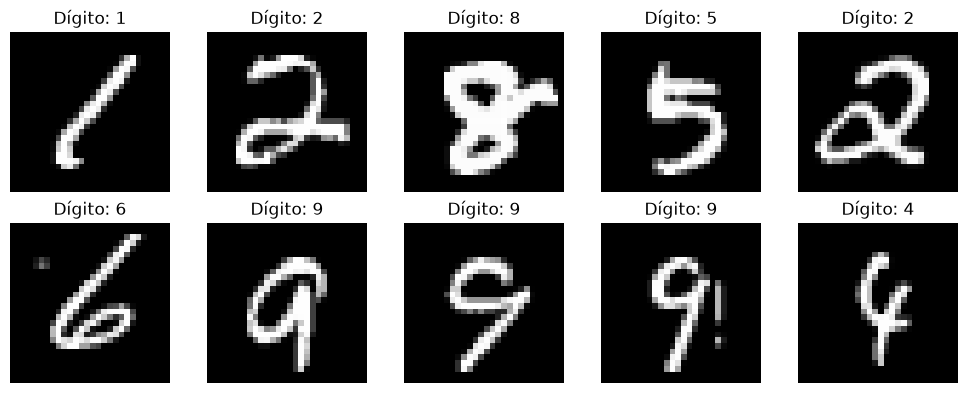

Shape: torch.Size([128, 1, 28, 28])
Pixel mínimo: 0.0
Pixel máximo: 1.0


In [3]:
images, labels = next(iter(train_loader))

fig, axes = plt.subplots(2, 5, figsize=(10, 4))

for i, ax in enumerate(axes.flat):
    ax.imshow(images[i].squeeze(), cmap="gray")
    ax.set_title(f"Dígito: {labels[i].item()}")
    ax.axis("off")

plt.tight_layout()
plt.show()

print("Shape:", images.shape)
print("Pixel mínimo:", images.min().item())
print("Pixel máximo:", images.max().item())

In [4]:
class Encoder(nn.Module):

    def __init__(self, latent_dim=16):
        super().__init__()

        self.conv = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=4, stride=2, padding=1),
            nn.ReLU(),

            nn.Conv2d(32, 64, kernel_size=4, stride=2, padding=1),
            nn.ReLU(),

            nn.Flatten()
        )

        self.fc = nn.Sequential(
            nn.Linear(64 * 7 * 7, 256),
            nn.ReLU()
        )

        self.fc_mu = nn.Linear(256, latent_dim)
        self.fc_logvar = nn.Linear(256, latent_dim)

    def forward(self, x):

        h = self.conv(x)
        h = self.fc(h)

        mu = self.fc_mu(h)
        logvar = self.fc_logvar(h)

        return mu, logvar

In [5]:
def reparameterize(mu, logvar):

    std = torch.exp(0.5 * logvar)

    epsilon = torch.randn_like(std)

    z = mu + std * epsilon

    return z

In [6]:
class Decoder(nn.Module):

    def __init__(self, latent_dim=16):
        super().__init__()

        self.fc = nn.Sequential(
            nn.Linear(latent_dim, 256),
            nn.ReLU(),

            nn.Linear(256, 64 * 7 * 7),
            nn.ReLU()
        )

        self.deconv = nn.Sequential(
            nn.Unflatten(1, (64, 7, 7)),

            nn.ConvTranspose2d(
                64, 32,
                kernel_size=4,
                stride=2,
                padding=1
            ),
            nn.ReLU(),

            nn.ConvTranspose2d(
                32, 1,
                kernel_size=4,
                stride=2,
                padding=1
            ),

            nn.Sigmoid()
        )

    def forward(self, z):

        h = self.fc(z)

        reconstruction = self.deconv(h)

        return reconstruction

In [7]:
class VAE(nn.Module):

    def __init__(self, latent_dim=16):
        super().__init__()

        self.encoder = Encoder(latent_dim)
        self.decoder = Decoder(latent_dim)

    def forward(self, x):

        mu, logvar = self.encoder(x)

        z = reparameterize(mu, logvar)

        reconstruction = self.decoder(z)

        return reconstruction, mu, logvar

In [8]:
model = VAE(latent_dim=16).to(device)

images, labels = next(iter(train_loader))
images = images.to(device)

reconstruction, mu, logvar = model(images)

print("Entrada:", images.shape)
print("Reconstrução:", reconstruction.shape)
print("Mu:", mu.shape)
print("Logvar:", logvar.shape)

Entrada: torch.Size([128, 1, 28, 28])
Reconstrução: torch.Size([128, 1, 28, 28])
Mu: torch.Size([128, 16])
Logvar: torch.Size([128, 16])


In [9]:
def reconstruction_loss(x, reconstruction):

    return F.binary_cross_entropy(
        reconstruction,
        x,
        reduction="sum"
    )

In [10]:
def kl_divergence(mu, logvar):

    return -0.5 * torch.sum(
        1 + logvar - mu.pow(2) - logvar.exp()
    )

In [11]:
def vae_loss(x, reconstruction, mu, logvar, beta=1.0):

    recon_loss = reconstruction_loss(x, reconstruction)

    kl_loss = kl_divergence(mu, logvar)

    total_loss = recon_loss + beta * kl_loss

    return total_loss, recon_loss, kl_loss

In [12]:
def train_epoch(model, loader, optimizer, device):

    model.train()

    total_loss = 0
    total_recon = 0
    total_kl = 0

    for x, _ in loader:

        x = x.to(device)

        optimizer.zero_grad()

        reconstruction, mu, logvar = model(x)

        loss, recon_loss, kl_loss = vae_loss(
            x, reconstruction, mu, logvar
        )

        loss.backward()

        optimizer.step()

        total_loss += loss.item()
        total_recon += recon_loss.item()
        total_kl += kl_loss.item()

    n = len(loader.dataset)

    return (
        total_loss / n,
        total_recon / n,
        total_kl / n
    )

In [13]:
def evaluate(model, loader, device):

    model.eval()

    total_loss = 0
    total_recon = 0
    total_kl = 0

    with torch.no_grad():

        for x, _ in loader:

            x = x.to(device)

            reconstruction, mu, logvar = model(x)

            loss, recon_loss, kl_loss = vae_loss(
                x, reconstruction, mu, logvar
            )

            total_loss += loss.item()
            total_recon += recon_loss.item()
            total_kl += kl_loss.item()

    n = len(loader.dataset)

    return (
        total_loss / n,
        total_recon / n,
        total_kl / n
    )

In [14]:
model = VAE(latent_dim=16).to(device)

optimizer = optim.Adam(
    model.parameters(),
    lr=1e-3
)

EPOCHS = 30

history = {
    "train_loss": [],
    "train_recon": [],
    "train_kl": [],
    "test_loss": [],
    "test_recon": [],
    "test_kl": []
}

for epoch in range(EPOCHS):

    train_metrics = train_epoch(
        model, train_loader, optimizer, device
    )

    test_metrics = evaluate(
        model, test_loader, device
    )

    history["train_loss"].append(train_metrics[0])
    history["train_recon"].append(train_metrics[1])
    history["train_kl"].append(train_metrics[2])

    history["test_loss"].append(test_metrics[0])
    history["test_recon"].append(test_metrics[1])
    history["test_kl"].append(test_metrics[2])

    print(
        f"Epoch [{epoch+1}/{EPOCHS}] "
        f"Train Loss: {train_metrics[0]:.2f} | "
        f"Recon: {train_metrics[1]:.2f} | "
        f"KL: {train_metrics[2]:.2f} | "
        f"Test Loss: {test_metrics[0]:.2f}"
    )

Epoch [1/30] Train Loss: 162.95 | Recon: 151.78 | KL: 11.17 | Test Loss: 118.39
Epoch [2/30] Train Loss: 112.48 | Recon: 92.74 | KL: 19.74 | Test Loss: 107.71
Epoch [3/30] Train Loss: 106.38 | Recon: 85.34 | KL: 21.04 | Test Loss: 103.92
Epoch [4/30] Train Loss: 103.60 | Recon: 81.96 | KL: 21.64 | Test Loss: 101.98
Epoch [5/30] Train Loss: 101.98 | Recon: 79.94 | KL: 22.04 | Test Loss: 101.41
Epoch [6/30] Train Loss: 100.90 | Recon: 78.71 | KL: 22.18 | Test Loss: 99.91
Epoch [7/30] Train Loss: 100.16 | Recon: 77.87 | KL: 22.29 | Test Loss: 99.54
Epoch [8/30] Train Loss: 99.51 | Recon: 77.16 | KL: 22.35 | Test Loss: 99.49
Epoch [9/30] Train Loss: 98.99 | Recon: 76.62 | KL: 22.37 | Test Loss: 99.01
Epoch [10/30] Train Loss: 98.57 | Recon: 76.16 | KL: 22.42 | Test Loss: 98.32
Epoch [11/30] Train Loss: 98.21 | Recon: 75.77 | KL: 22.44 | Test Loss: 98.26
Epoch [12/30] Train Loss: 97.88 | Recon: 75.44 | KL: 22.44 | Test Loss: 97.83
Epoch [13/30] Train Loss: 97.51 | Recon: 75.04 | KL: 22.47 |

In [17]:
model.eval()

images, labels = next(iter(test_loader))
images = images.to(device)

with torch.no_grad():

    # Encoder
    mu, logvar = model.encoder(images)

    # Utilizamos a média como representação latente
    reconstruction = model.decoder(mu)

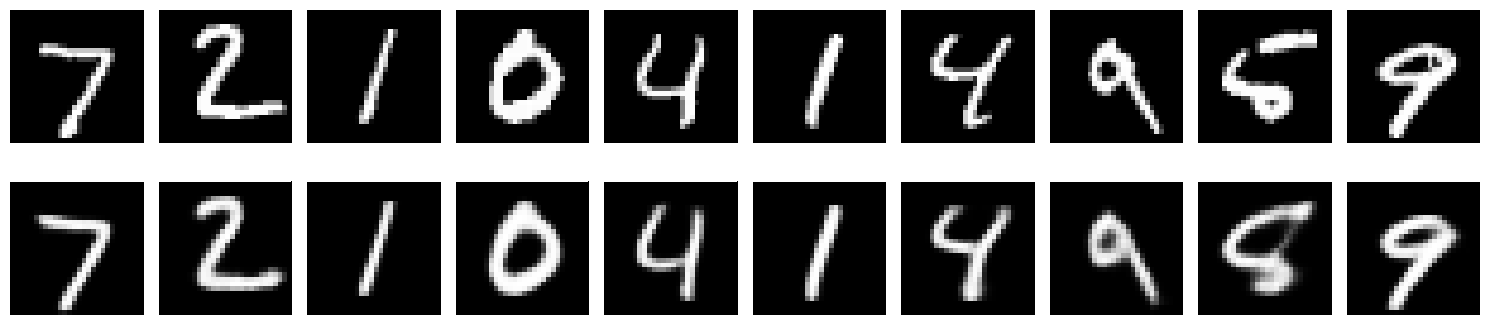

In [18]:
n = 10

fig, axes = plt.subplots(2, n, figsize=(15, 4))

for i in range(n):

    # Imagem original
    axes[0, i].imshow(
        images[i].cpu().squeeze(),
        cmap="gray"
    )
    axes[0, i].axis("off")

    # Imagem reconstruída
    axes[1, i].imshow(
        reconstruction[i].cpu().squeeze(),
        cmap="gray"
    )
    axes[1, i].axis("off")

axes[0, 0].set_ylabel("Original", fontsize=12)
axes[1, 0].set_ylabel("Reconstrução", fontsize=12)

plt.tight_layout()
plt.show()

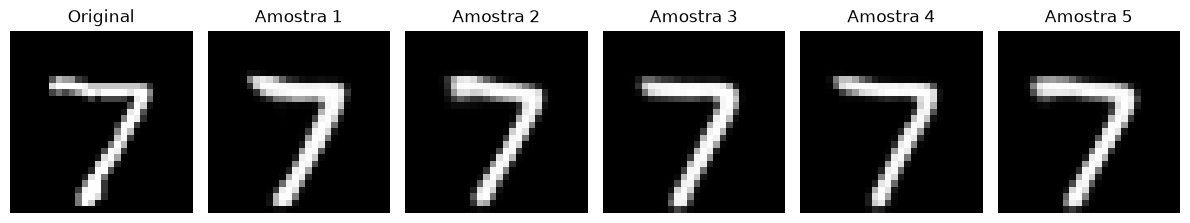

In [19]:
model.eval()

image = images[0].unsqueeze(0)

fig, axes = plt.subplots(1, 6, figsize=(12, 3))

with torch.no_grad():

    mu, logvar = model.encoder(image)

    # Primeira imagem: original
    axes[0].imshow(
        image.cpu().squeeze(),
        cmap="gray"
    )
    axes[0].set_title("Original")
    axes[0].axis("off")

    # Outras imagens: diferentes amostragens
    for i in range(1, 6):

        z = reparameterize(mu, logvar)

        reconstruction = model.decoder(z)

        axes[i].imshow(
            reconstruction.cpu().squeeze(),
            cmap="gray"
        )

        axes[i].set_title(f"Amostra {i}")
        axes[i].axis("off")

plt.tight_layout()
plt.show()

In [20]:
model.eval()

n_samples = 20
latent_dim = 16

with torch.no_grad():

    # Amostrar diretamente do prior
    z = torch.randn(
        n_samples,
        latent_dim,
        device=device
    )

    # Gerar imagens
    generated = model.decoder(z)

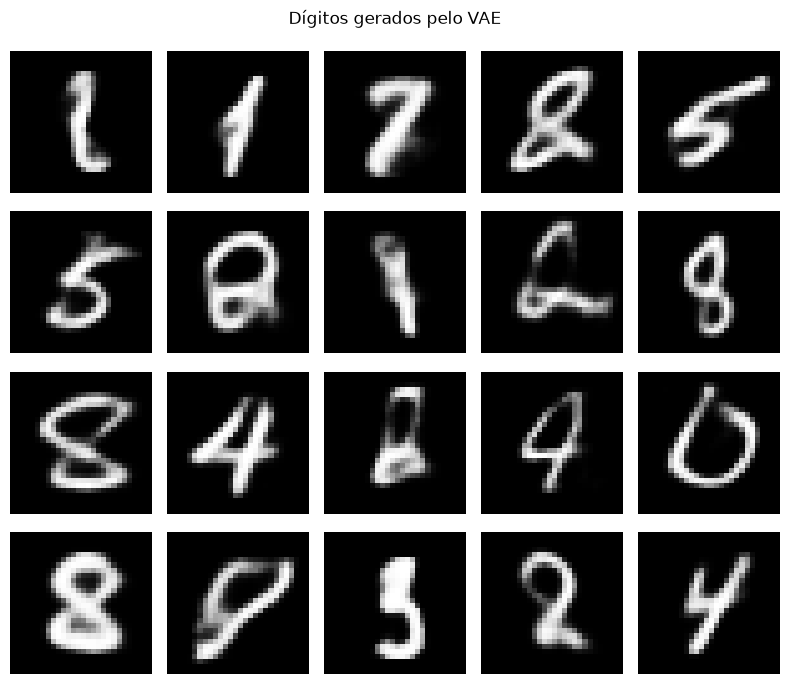

In [21]:
fig, axes = plt.subplots(4, 5, figsize=(8, 7))

for i, ax in enumerate(axes.flat):

    ax.imshow(
        generated[i].cpu().squeeze(),
        cmap="gray"
    )

    ax.axis("off")

plt.suptitle("Dígitos gerados pelo VAE")
plt.tight_layout()
plt.show()

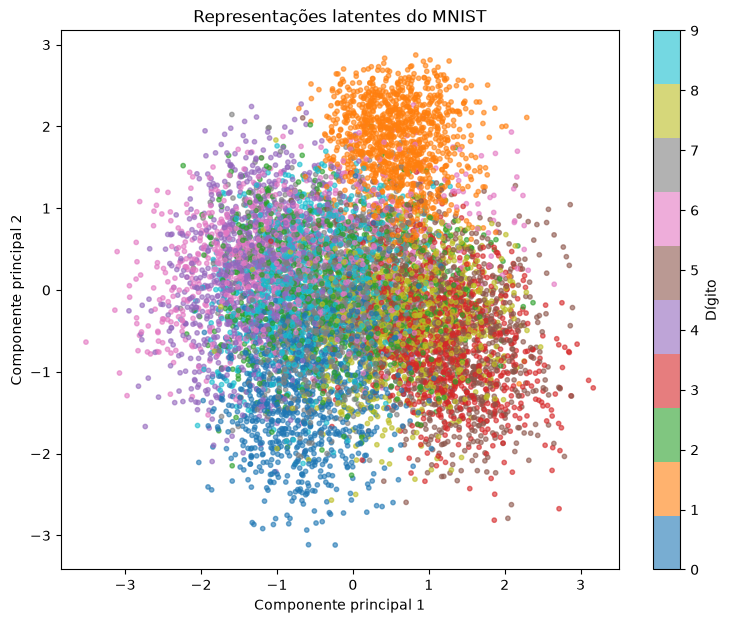

In [22]:
from sklearn.decomposition import PCA

model.eval()

all_mu = []
all_labels = []

with torch.no_grad():

    for x, y in test_loader:

        x = x.to(device)

        mu, logvar = model.encoder(x)

        all_mu.append(mu.cpu().numpy())
        all_labels.append(y.numpy())

all_mu = np.concatenate(all_mu)
all_labels = np.concatenate(all_labels)

# Redução para duas dimensões
pca = PCA(n_components=2)

mu_2d = pca.fit_transform(all_mu)

# Visualização
plt.figure(figsize=(9, 7))

scatter = plt.scatter(
    mu_2d[:, 0],
    mu_2d[:, 1],
    c=all_labels,
    cmap="tab10",
    alpha=0.6,
    s=10
)

plt.colorbar(scatter, label="Dígito")
plt.xlabel("Componente principal 1")
plt.ylabel("Componente principal 2")
plt.title("Representações latentes do MNIST")
plt.show()

In [23]:
model.eval()

with torch.no_grad():

    mu, logvar = model.encoder(image)

    std = torch.exp(0.5 * logvar)

    print("Média de mu:", mu.mean().item())
    print("Desvio padrão de mu:", mu.std().item())

    print("Média de std:", std.mean().item())
    print("Menor std:", std.min().item())
    print("Maior std:", std.max().item())

Média de mu: -0.1219320148229599
Desvio padrão de mu: 0.910703718662262
Média de std: 0.41188812255859375
Menor std: 0.06544692814350128
Maior std: 0.9883989691734314


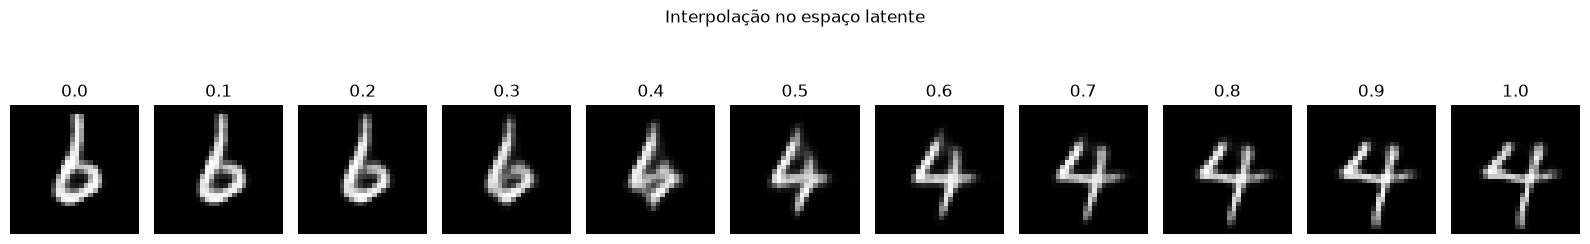

In [24]:
model.eval()

latent_dim = 16

with torch.no_grad():

    # Duas amostras aleatórias do prior
    z_a = torch.randn(1, latent_dim, device=device)
    z_b = torch.randn(1, latent_dim, device=device)

    # Valores de interpolação
    alphas = torch.linspace(0, 1, 11)

    interpolated_images = []

    for alpha in alphas:

        z = (1 - alpha) * z_a + alpha * z_b

        generated = model.decoder(z)

        interpolated_images.append(
            generated.cpu().squeeze().numpy()
        )

# Visualização
fig, axes = plt.subplots(1, 11, figsize=(16, 3))

for i, ax in enumerate(axes):

    ax.imshow(interpolated_images[i], cmap="gray")

    ax.set_title(f"{alphas[i]:.1f}")
    ax.axis("off")

plt.suptitle("Interpolação no espaço latente")
plt.tight_layout()
plt.show()

In [ ]:
model.eval()

all_mu = []
all_std = []
all_kl = []

with torch.no_grad():

    for x, _ in test_loader:

        x = x.to(device)

        mu, logvar = model.encoder(x)

        std = torch.exp(0.5 * logvar)

        # KL individual por dimensão
        kl_per_dim = 0.5 * (
            mu.pow(2) + logvar.exp() - 1 - logvar
        )

        all_mu.append(mu.cpu())
        all_std.append(std.cpu())
        all_kl.append(kl_per_dim.cpu())

all_mu = torch.cat(all_mu, dim=0)
all_std = torch.cat(all_std, dim=0)
all_kl = torch.cat(all_kl, dim=0)

print("Média de mu por dimensão:")
print(all_mu.mean(dim=0))

print("\nDesvio padrão de mu por dimensão:")
print(all_mu.std(dim=0))

print("\nMédia de sigma por dimensão:")
print(all_std.mean(dim=0))

print("\nKL média por dimensão:")
print(all_kl.mean(dim=0))

Média de mu por dimensão:
tensor([-0.0513, -0.0318,  0.1981, -0.0282, -0.0653, -0.0978,  0.1431, -0.0114,
        -0.0306,  0.0085, -0.0358,  0.0211,  0.0675,  0.0274, -0.0307, -0.1427])

Desvio padrão de mu por dimensão:
tensor([0.9710, 0.0190, 0.9728, 0.8854, 0.8847, 0.7755, 0.9533, 0.8698, 0.8811,
        0.9940, 0.9607, 0.9481, 1.0035, 1.0091, 0.8875, 0.7552])

Média de sigma por dimensão:
tensor([0.0699, 0.9900, 0.2297, 0.3235, 0.3954, 0.5914, 0.2168, 0.3493, 0.3611,
        0.1982, 0.1343, 0.1779, 0.1096, 0.0789, 0.3880, 0.5845])

KL média por dimensão:
tensor([2.6583e+00, 8.5120e-04, 1.5031e+00, 1.1755e+00, 9.7643e-01, 5.5016e-01,
        1.5487e+00, 1.0812e+00, 1.0645e+00, 1.7919e+00, 2.0075e+00, 1.7941e+00,
        2.2534e+00, 2.5869e+00, 9.9716e-01, 5.4943e-01])


: 